# HW2 · The Formalizer: ¿traducir a CSP o responder directo?
**Equipo: Daniel Salazar, Andretty Ochoa y Jalil Chano · CMP-4004 · USFQ · 18 de noviembre de 2026**

**Pregunta:** si un modelo de lenguaje pequeño (`qwen2.5:3b`, local) traduce un acertijo a un modelo CSP y un solver lo resuelve, ¿acierta más que si responde directo? Y sobre todo: **cuando falla, ¿nos damos cuenta?**

Cuatro brazos sobre los mismos 21 problemas propios (7 fáciles, 7 medios, 7 difíciles) y 3 semillas:
**A** modelo a mano → solver · **B** LLM → modelo → solver · **B′** B con hasta 3 rondas de mensajes del solver · **C** LLM responde directo.

Este notebook no vuelve a llamar al modelo: lee `results/` y `fig/`. El reporte completo está en `REPORT.md`.

In [1]:
import csv, json, sys, subprocess
from collections import Counter
from pathlib import Path
from IPython.display import Image, Markdown, display
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "code"))
from resultados import leer, TAXONOMIA
from scorecard import calcular, tabla
filas = leer()
print(Counter((f["brazo"]) for f in filas))

Counter({'A': 63, 'B': 63, 'Bp': 63, 'C': 63})


## 1. El dataset y el brazo A (el techo)

In [2]:
subprocess.run([sys.executable, "code/verificar_dataset.py"], check=False)

CompletedProcess(args=['C:\\Users\\salaz\\OneDrive\\Documents\\USFQ semestre 7\\IA\\cmp-4004-fall26\\.venv\\Scripts\\python.exe', 'code/verificar_dataset.py'], returncode=0)

## 2. Duel Scorecard

In [3]:
display(Markdown(tabla(calcular(filas))))

| Eje | A · a mano | B · híbrido | B′ · refinamiento | C · directo |
|---|---|---|---|---|
| 1 Correctness | 63/63 (100 %) | 3/63 (5 %) | 6/63 (10 %) | 3/63 (5 %) |
| 2 Guarantee | Correcta y única si el modelo a mano es fiel (el solver es completo). | Correcta y única si la traducción es fiel; ninguna sobre la traducción. | Igual que B; solo corrige lo que el solver ve. | Ninguna; no hay certificado. |
| 3 Cost | 0 tokens | 42132 tokens/correcta | 106929 tokens/correcta | 10813 tokens/correcta |
| 4 Latency | mediana 0.00 s · p95 0.00 s | mediana 9.97 s · p95 26.30 s | mediana 40.62 s · p95 106.79 s | mediana 7.49 s · p95 10.64 s |
| 5 Reproducibility | 1.00 respuestas distintas por problema; 21/21 estables | 1.95 respuestas distintas por problema; 2/21 estables | 1.81 respuestas distintas por problema; 6/21 estables | 2.62 respuestas distintas por problema; 3/21 estables |
| 6 Scaling | facil 100 % → medio 100 % → dificil 100 % | facil 14 % → medio 0 % → dificil 0 % | facil 24 % → medio 5 % → dificil 0 % | facil 14 % → medio 0 % → dificil 0 % |
| 7 Interpretability | Total: modelo JSON revisable. | Alta: el modelo JSON es un certificado; se ve qué pista falló. | Alta, más la traza de mensajes del solver. | Baja: solo una asignación final. |
| 8 Failure mode | sin fallos | sintaxis 36, sobre_restringido 11, aridad_alcance 10, sub_restringido 3 · **detectables sin gold: 60/60** | sintaxis 22, sobre_restringido 17, aridad_alcance 15, sub_restringido 2 · **detectables sin gold: 56/57** | incorrecta 46, incompleta 14 · **detectables sin gold: 14/60** |

## 3. Precisión vs. dificultad

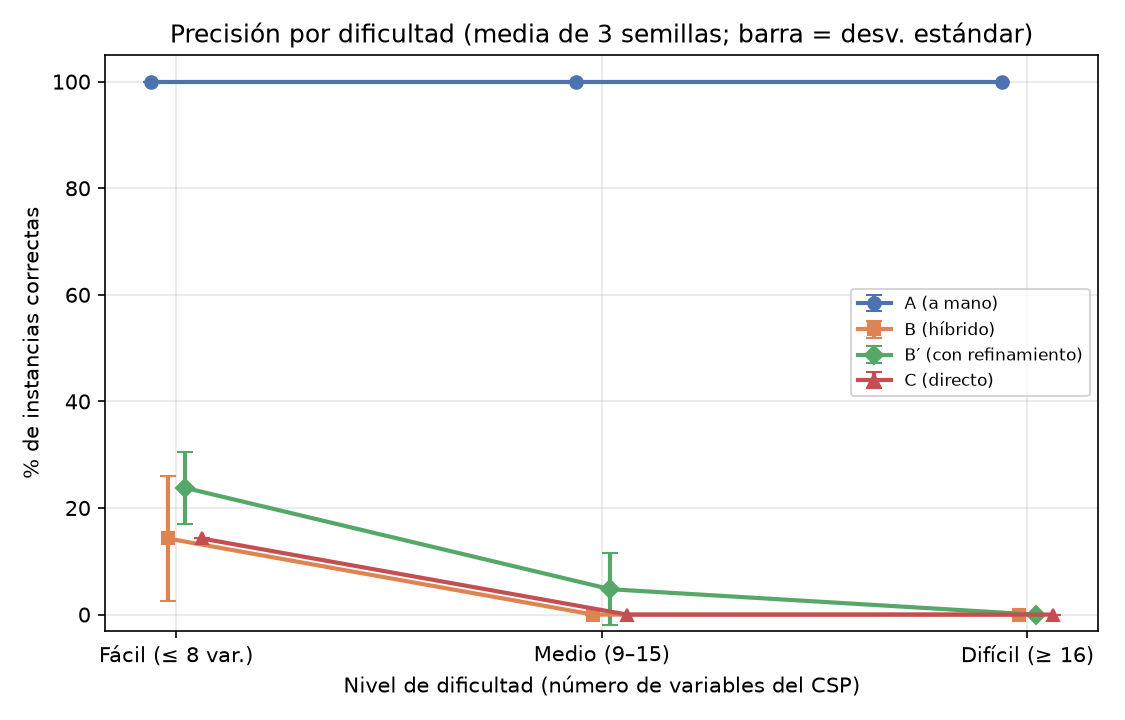

In [4]:
display(Image(filename="fig/precision_vs_dificultad.png"))

## 4. Taxonomía de errores del brazo B y la columna que importa: ¿se detecta sin la respuesta correcta?

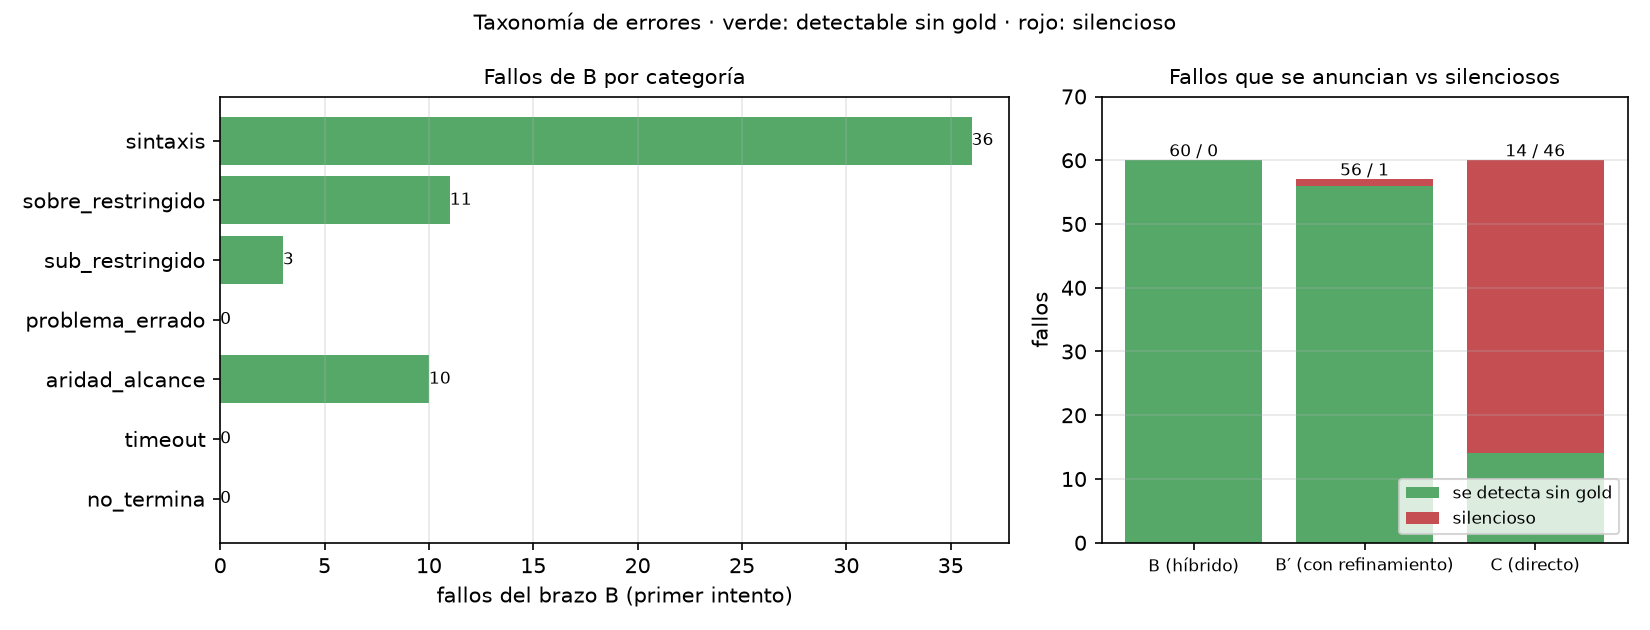

B: 60 fallos, 60 detectables sin gold, 0 silenciosos
C: 60 fallos, 14 detectables sin gold, 46 silenciosos


In [5]:
display(Image(filename="fig/taxonomia_b.png"))
for brazo in ("B", "C"):
    fallos = [f for f in filas if f["brazo"] == brazo and f["resultado"] != "correcto"]
    det = sum(f["detectable"] == "si" for f in fallos)
    print(f"{brazo}: {len(fallos)} fallos, {det} detectables sin gold, {len(fallos) - det} silenciosos")

### Ejemplos verbatim de salidas del modelo (brazo B)

In [6]:
intentos = [json.loads(l) for l in open("results/intentos_b.jsonl", encoding="utf-8")]
vistos = set()
for it in intentos:
    if it["iteracion"] == 1 and it["categoria"] and it["categoria"] not in vistos:
        vistos.add(it["categoria"])
        print(f"--- {it['problema_id']} semilla {it['semilla']} · {it['categoria']}")
        print("solver:", it["mensaje_solver"] or "(solución única)")
        print(it["salida"][:700], "\n")

--- facil-01 semilla 2 · sobre_restringido
solver: The solver proved the model has NO solution: some constraint is wrong or too strong. Removing any ONE of these constraints would make it solvable, so check them against the puzzle: {"clue": 1, "type": "eq", "a": "Mateo", "b": "Red"}; {"clue": 5, "type": "offset", "a": "Red", "b": "Yellow", "k": 1}.
{"variables": {"Mateo": [1, 2, 3], "Sofía": [1, 2, 3], "Lucas": [1, 2, 3], "Red": [1, 2, 3], "Yellow": [1, 2, 3], "Blue": [1, 2, 3]}, "constraints": [{"clue": 0, "type": "alldiff", "vars": ["Mateo", "Sofía", "Lucas"]}, {"clue": 0, "type": "alldiff", "vars": ["Red", "Yellow", "Blue"]}, {"clue": 1, "type": "eq", "a": "Mateo", "b": "Red"}, {"clue": 2, "type": "offset", "a": "Sofía", "b": "Mateo", "k": 1}, {"clue": 3, "type": "eq", "a": "Lucas", "b": 3}, {"clue": 4, "type": "adj", "a": "Yellow", "b": "Blue"}, {"clue": 5, "type": "offset", "a": "Red", "b": "Yellow", "k": 1}]} 

--- facil-02 semilla 0 · sintaxis
solver: Your output could not be pa

## 5. Refinamiento: ¿sirve el mensaje del solver como señal de aprendizaje?

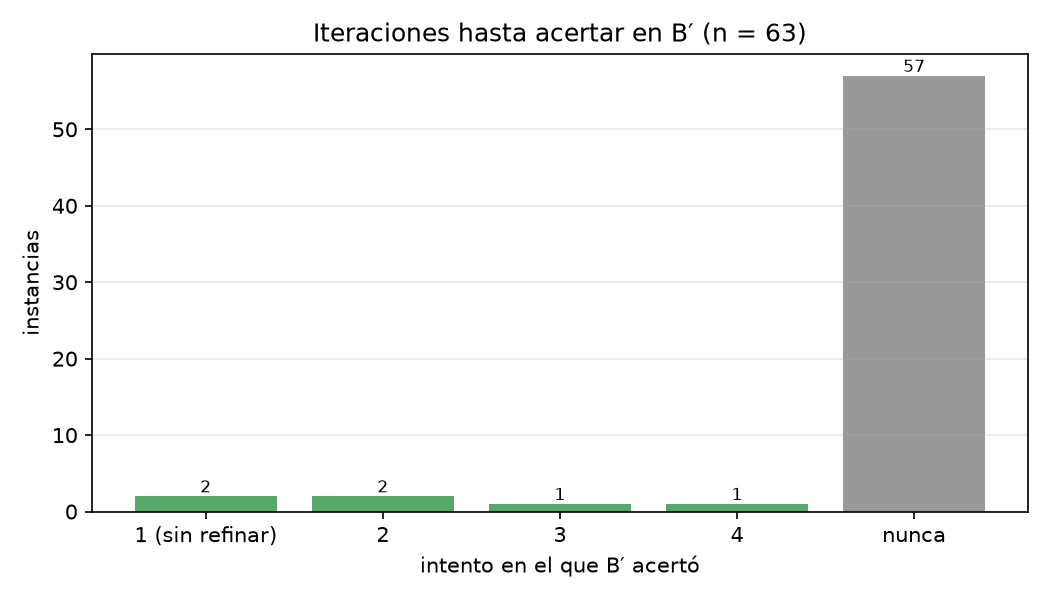

# Análisis para el REPORT

## Refinamiento (B')

- B: 3/63 (5 %) · B': 6/63 (10 %) · delta = 3 instancias

| Iteraciones hasta acertar | Instancias |
|---|---|
| 1 | 2 |
| 2 | 2 |
| 3 | 1 |
| 4 | 1 |
| nunca convergió | 57 |

- Primer error de los que el refinamiento arregló: {'': 1, 'sintaxis': 3}
- Primer error de los que sobrevivieron 3 rondas con un error visible: {'sintaxis': 33, 'aridad_alcance': 10, 'sobre_restringido': 10, 'sub_restringido': 3}

## Detectabilidad: B vs C

| Brazo | Fallos | Detectables sin gold | Silenciosos |
|---|---|---|---|
| B | 60 | 60 | 0 |
| C | 60 | 14 | 46 |

- Errores de C por tipo: {'incorrecta': 46, 'incompleta': 14} (detectable según {'sin_formato': 'si', 'incompleta': 'si', 'incorrecta': 'no', 'no_termina': 'si'})

In [7]:
display(Image(filename="fig/iteraciones_bp.png"))
display(Markdown(open("results/analisis.md", encoding="utf-8").read()))

## 6. Costo por respuesta correcta

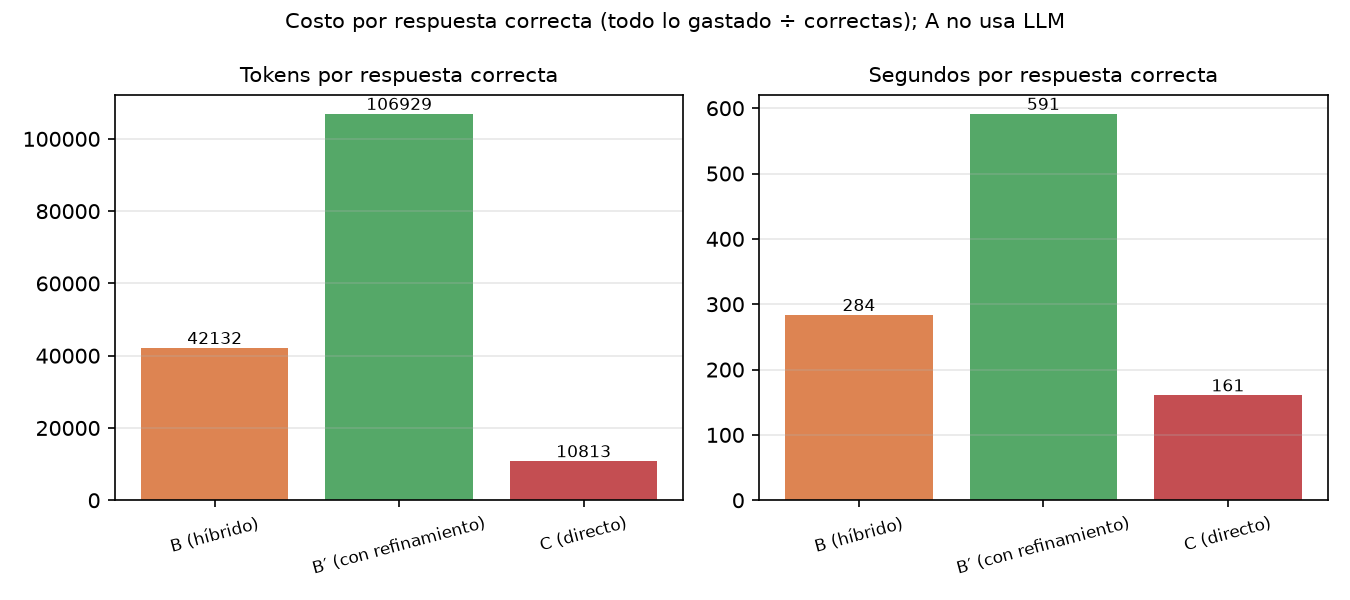

# Costo por respuesta correcta

**together** · `Qwen3.5 9B` · $0.17/M entrada, $0.25/M salida · https://www.together.ai/pricing (consultado 2026-11-18)

| Brazo | Intentos | Correctas | Tokens | USD total | USD por correcta | s por correcta |
|---|---|---|---|---|---|---|
| A | 63 | 63 | 0 | 0.000000 | 0.000000 | 0.0 |
| B | 63 | 3 | 126396 | 0.025949 | 0.008650 | 283.6 |
| Bp | 63 | 6 | 641572 | 0.126088 | 0.021015 | 591.4 |
| C | 63 | 3 | 32440 | 0.006045 | 0.002015 | 160.6 |


In [8]:
display(Image(filename="fig/costo_por_correcta.png"))
display(Markdown(open("results/costos.md", encoding="utf-8").read()))

## 7. Dónde se va el tiempo

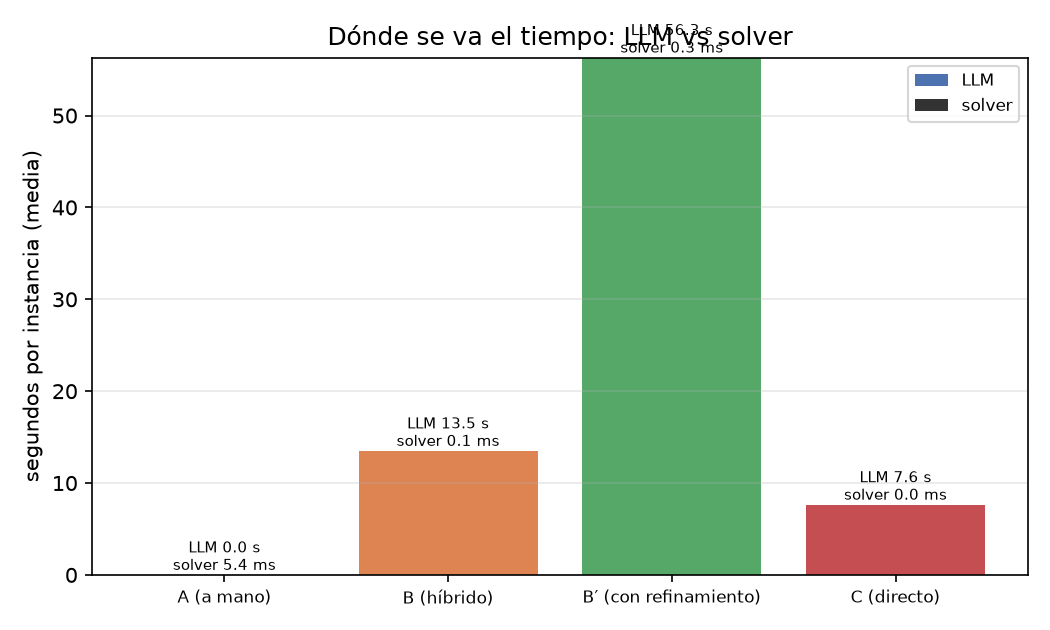

In [9]:
display(Image(filename="fig/tiempo_llm_vs_solver.png"))

## 8. Las pruebas del código pasan

In [10]:
subprocess.run([sys.executable, "code/tests/test_base.py"], check=False)

CompletedProcess(args=['C:\\Users\\salaz\\OneDrive\\Documents\\USFQ semestre 7\\IA\\cmp-4004-fall26\\.venv\\Scripts\\python.exe', 'code/tests/test_base.py'], returncode=0)

## 9. Conclusión
Las conclusiones, el análisis de dónde pudimos ser injustos y la recomendación de despliegue están en `REPORT.md`, secciones 6 y 7.